# Customer Support Analysis

**Team:** TwoSeven

**Member:** Lucas Liu, Weijun Fan, Shujun Chen

### Background
Many customers tweet a brand for help when their products go wrong. In late 2017, support teams faced two very different surges: Apple’s iOS 11.1 keyboard bug (released Oct 31, fixed Nov 9) and Amazon’s Black Friday (Nov 24) and Cyber Monday (Nov 27).

### Research Problem
1. Does the posting time and words affect the influence the response speed?
    - Morning or Night
    - Rude or Polite
2. How do support teams react a planned peak vs an unplanned emergency?
    - Planned Black Friday vs iOS 11.1 keyboard bug
3. Which similar-case search methods is helpful?
    - keywords (TF-IDF) or semantic embeddings

### Delivery
We will diliver a system that accept a customer's query about the products, and then provide the expected waiting time accodring to the users' word, posting time and whether it is a peak time, and provide a few related cases for user to review while they are waiting.

## Data Cleaning

### 1. Read Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("./data/twcs/twcs.csv")
print("Data Shape: ", df.shape)
df.head()

Data Shape:  (2811774, 7)


,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id
0,1,sprintcare,False,Tue Oct 31 22:10:47 +0000 2017,@115712 I understand. I would like to assist y...,2,3.0
1,2,115712,True,Tue Oct 31 22:11:45 +0000 2017,@sprintcare and how do you propose we do that,NaN,1.0
2,3,115712,True,Tue Oct 31 22:08:27 +0000 2017,@sprintcare I have sent several private messag...,1,4.0
3,4,sprintcare,False,Tue Oct 31 21:54:49 +0000 2017,@115712 Please send us a Private Message so th...,3,5.0
4,5,115712,True,Tue Oct 31 21:49:35 +0000 2017,@sprintcare I did.,4,6.0


There are 281,1774 data, each row is a tweet, contains 7 columns:
- `tweet_id`: The unique ID of the tweet.
- `author_id`: The ID or account name of the person or support team that posted the tweet.
- `inbound`: Whether the tweet was sent to a company. `True`: a customer message. `False`: a support message.
- `created_at`: The date and time when the tweet was posted.
- `text`: The text of the tweet.
- `response_tweet_id`: The ID(s) of tweets that replied to this tweet, if any.
- `in_response_to_tweet_id`: The ID of the tweet that this tweet replied to, if any.

### 2. Check Missing and Duplicate Data

In [3]:
# Calculate the missing data count
print("Missing Count:")
print(df.isnull().sum())

both_missing = df[df["response_tweet_id"].isnull() & df["in_response_to_tweet_id"].isnull()]
print("Tweets with both IDs missing:", both_missing.shape[0])

Missing Count:
tweet_id                         0
author_id                        0
inbound                          0
created_at                       0
text                             0
response_tweet_id          1040629
in_response_to_tweet_id     794335
dtype: int64
Tweets with both IDs missing: 0


- Missing `response_tweet_id`: last tweet of a series of converstation.
- Missing `in_response_to_tweet_id`: start of a series of conversation.
- Both are missing: neither field records a reply link, so the tweet may be a standalone message.

Missing IDs do not tell us whether the author is a customer or a support account, `inbound` column tell us these.

In [4]:
print("Exact duplicate rows:", df.duplicated().sum())

id_counts = df["tweet_id"].value_counts()
print("Number of repeated tweet IDs:", (id_counts > 1).sum())

Exact duplicate rows: 0
Number of repeated tweet IDs: 0


### 3. Brand Statistics

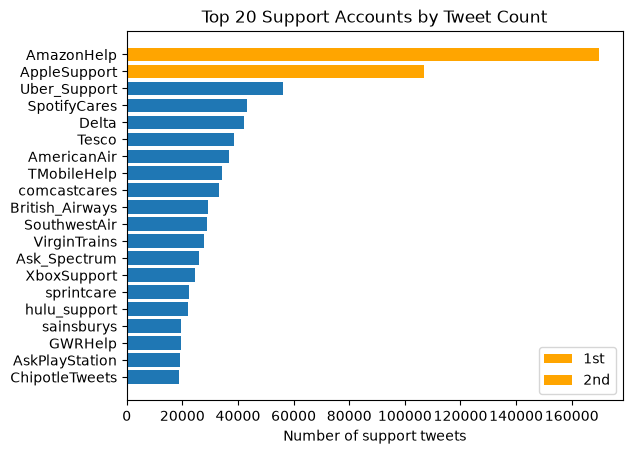

In [5]:
support_tweets = df[df["inbound"] == False]
brand_counts = pd.DataFrame({"Support Tweet Count": support_tweets["author_id"].value_counts()})
top_brands = brand_counts.head(20).sort_values("Support Tweet Count")

plt.barh(top_brands.index, top_brands["Support Tweet Count"])
plt.barh(top_brands.index[-1], top_brands["Support Tweet Count"].iloc[-1], color="orange", label="1st")
plt.barh(top_brands.index[-2], top_brands["Support Tweet Count"].iloc[-2], color="orange", label="2nd")
plt.xlabel("Number of support tweets")
plt.title("Top 20 Support Accounts by Tweet Count")
plt.legend()
plt.show()

The chart shows the 20 support accounts with the most tweets. 

AmazonHelp has the most support tweets, followed by AppleSupport. 
For the rest of this project, we will study only Amazon and Apple, including their support tweets and related customer messages.

Next, we need to assign the related brand to each tweet, then we can delete the orther brand tweet safely.

The Algorithm is:
- first assign those tweet from a support account.
- While there are still tweets without a related brand:
    - propagate the brand that newly assigned last iteration to its parent tweets and its replies.

In [6]:
def find_related_brands(data):
    """Fill unknown brands one reply step at a time using pandas.
    Keep the first assigned brand and return a Series aligned with data.
    """
    # First label the support tweet.
    messages = data[["tweet_id", "in_response_to_tweet_id"]].copy()
    messages["related_brand"] = data["author_id"].where(data["inbound"] == False)
    # Now, only support tweets have the label.
    # new_labels is the latest updated data every iteration.
    new_labels = messages[messages["related_brand"].notna()]
    # unknown is those who haven't been updated.
    unknown = messages[messages["related_brand"].isna()].copy()

    # Only newly labeled tweets need to pass their brand to unknown tweets.
    while not new_labels.empty and not unknown.empty:
        parent_brand = new_labels.set_index("tweet_id")["related_brand"]
        reply_brand = new_labels.groupby("in_response_to_tweet_id")["related_brand"].first()
        # Within each round, use the parent's brand before a reply's brand.
        unknown["related_brand"] = unknown["in_response_to_tweet_id"].map(parent_brand)
        unknown["related_brand"] = unknown["related_brand"].fillna(unknown["tweet_id"].map(reply_brand))
        new_labels = unknown[unknown["related_brand"].notna()]
        messages.loc[new_labels.index, "related_brand"] = new_labels["related_brand"]
        unknown = unknown[unknown["related_brand"].isna()].copy()

    return messages["related_brand"]

cleaned_df = df.copy()

# Add brand labels, then keep tweets related to Amazon or Apple.
cleaned_df["related_brand"] = find_related_brands(cleaned_df)
print("Tweets before filtering:", cleaned_df.shape[0])
cleaned_df = cleaned_df[cleaned_df["related_brand"].isin(["AmazonHelp", "AppleSupport"])]
print("Tweets after filtering:", cleaned_df.shape[0])
cleaned_df.head()

Tweets before filtering: 2811774
Tweets after filtering: 611145


,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id,related_brand
181,269,AmazonHelp,False,Wed Nov 22 09:23:01 +0000 2017,@115770 こんにちは、アマゾン公式です。Fire TV Stickが見れないというのは...,"270,271",272.0,AmazonHelp
182,270,115770,True,Wed Nov 22 09:24:30 +0000 2017,@AmazonHelp ありがとうございます。\n今、電話で主人が対応していただいてます。,NaN,269.0,AmazonHelp
183,271,115770,True,Wed Nov 22 09:30:36 +0000 2017,@AmazonHelp 電話で対応してもらいましたが改良されませんでした。\n保証期間も過ぎ...,273,269.0,AmazonHelp
184,273,AmazonHelp,False,Wed Nov 22 09:40:27 +0000 2017,@115770 カスタマーサービスにてお問い合わせ済みとのことで、お手数をおかけいたしました...,274,271.0,AmazonHelp
185,274,115770,True,Wed Nov 22 09:44:04 +0000 2017,@AmazonHelp こちらこそありがとうございました。,275,273.0,AmazonHelp


### 4. Check Data Types

In [7]:
print("Data Type:")
print(cleaned_df.dtypes)

Data Type:
tweet_id                     int64
author_id                      str
inbound                       bool
created_at                     str
text                           str
response_tweet_id              str
in_response_to_tweet_id    float64
related_brand                  str
dtype: object


- `tweet_id` is `int64`: it contains integer IDs with no missing values.
- `in_response_to_tweet_id` is `float64`: it contains missing values (`NaN`), which regular `int64` cannot store.
- `response_tweet_id` is `str`: some values contain several reply IDs separated by commas, such as `"5,7"`.
- `created_at` is `str`: it is a timestamp in the string form, which cannot do the subtracting calculation.

So, we turn `tweet_id` and `in_response_to_tweet_id` into `Int64`, turn `response_tweet_id` into a list of `int`, turn `created_at` into `datetime`.

In [8]:
# Convert the str into list
response_ids = []
for response in cleaned_df["response_tweet_id"].fillna(""):
    response_ids.append([int(x) for x in response.split(",") if x != ""])
cleaned_df["response_tweet_id"] = response_ids

# Change type to Int64 (can store NaN)
cleaned_df["tweet_id"] = cleaned_df["tweet_id"].astype("Int64")
cleaned_df["in_response_to_tweet_id"] = cleaned_df["in_response_to_tweet_id"].astype("Int64")

# Change type to datetime
cleaned_df["created_at"] = pd.to_datetime(cleaned_df["created_at"], format="%a %b %d %H:%M:%S %z %Y", utc=True)

print("Data Type:")
print(cleaned_df.dtypes)

Data Type:
tweet_id                                 Int64
author_id                                  str
inbound                                   bool
created_at                 datetime64[us, UTC]
text                                       str
response_tweet_id                       object
in_response_to_tweet_id                  Int64
related_brand                              str
dtype: object


### 5. Check Time Range

Earliest tweet: 2011-10-13 11:57:18+00:00
Latest tweet: 2017-12-03 23:13:02+00:00


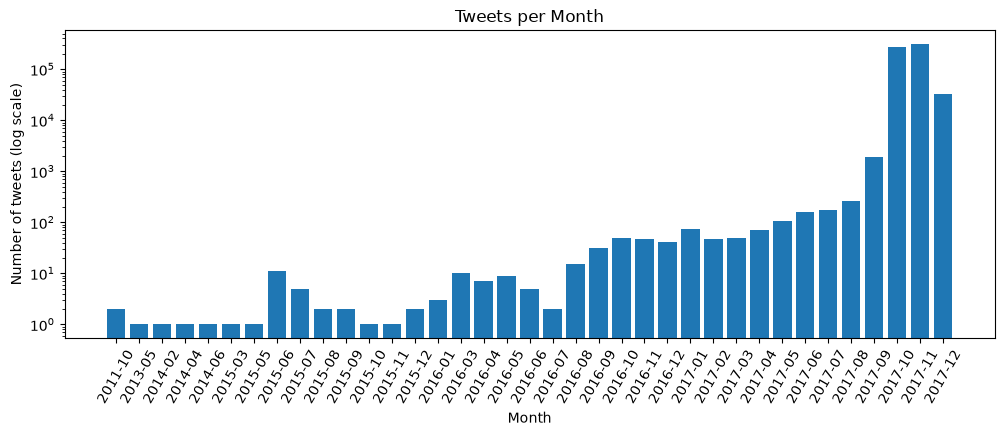

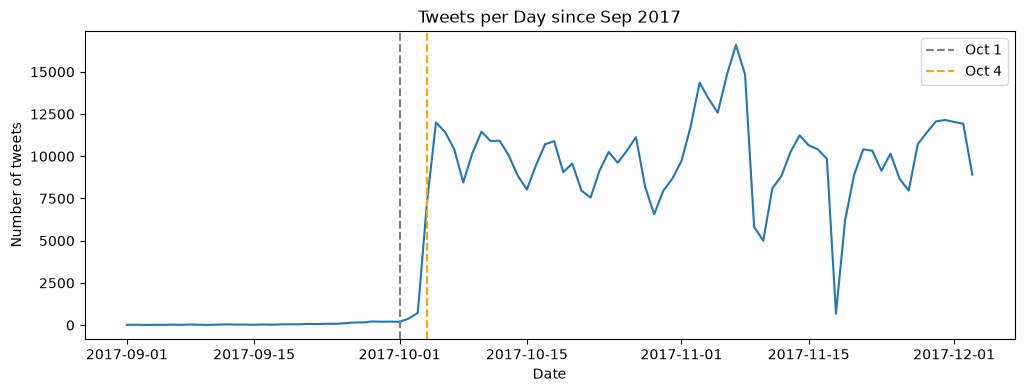

In [9]:
print("Earliest tweet:", cleaned_df["created_at"].min())
print("Latest tweet:", cleaned_df["created_at"].max())

# Count tweets per month (log scale, because early months are very small)
month_counts = pd.DataFrame({"Tweet Count": cleaned_df["created_at"].dt.strftime("%Y-%m").value_counts().sort_index()})

plt.figure(figsize=(12, 4))
plt.bar(month_counts.index, month_counts["Tweet Count"])
plt.yscale("log")
plt.xticks(rotation=60)
plt.xlabel("Month")
plt.ylabel("Number of tweets (log scale)")
plt.title("Tweets per Month")
plt.show()

# Zoom in: count tweets per day since Sep 2017
recent = cleaned_df[cleaned_df["created_at"] >= "2017-09-01"]
day_counts = recent["created_at"].dt.date.value_counts().sort_index()

plt.figure(figsize=(12, 4))
plt.plot(day_counts.index, day_counts.values)
plt.axvline(pd.Timestamp("2017-10-01"), color="gray", linestyle="--", label="Oct 1")
plt.axvline(pd.Timestamp("2017-10-04"), color="orange", linestyle="--", label="Oct 4")
plt.xlabel("Date")
plt.ylabel("Number of tweets")
plt.title("Tweets per Day since Sep 2017")
plt.legend()
plt.show()

Most tweets are from October to early December 2017. Before that, each month has only a fewtweets.

- These early tweets are scattered. They were likely pulled in because later conversations replied to them.
- The daily count jumps from a few hundred to over 6,000 on Oct 4, 2017, so continuous data collection starts there.
- We keep tweets from Oct 4, 2017 onward and remove the earlier ones.
- Both events for RQ2 come after this date: the iOS 11.1 keyboard bug (Oct 31 - Nov 9) and Black Friday / Cyber Monday (Nov 24 - Nov 27). Oct 4 - Oct 30 can serve as a normal period for comparison.

In [10]:
print("Tweets before filtering:", cleaned_df.shape[0])
# Keep tweets from Oct 4, 2017
cleaned_df = cleaned_df[cleaned_df["created_at"] >= "2017-10-04"]
print("Tweets after filtering:", cleaned_df.shape[0])
print("Earliest tweet:", cleaned_df["created_at"].min())

Tweets before filtering: 611145
Tweets after filtering: 606758
Earliest tweet: 2017-10-04 00:00:00+00:00


### 6. Detect Language

Some tweets are not in English.
Our text analysis (rude or polite words, TF-IDF, embeddings) only works for English, so we check the language of each tweet.

We use the characters in the text to guess the language:
- Hiragana or Katakana: Japanese (`japan`)
- Hangul: Korean (`korean`)
- Chinese characters: Chinese (`china`)
- Latin letters only: English or other western languages (`latin`)
- None of the above: `other`

Mentions (`@xxx`) and links are removed first, because they are always in Latin letters.

In [11]:
text = cleaned_df["text"].str.replace(r"@\w+|https?://\S+", "", regex=True)

cleaned_df["language"] = np.select(
    [text.str.contains("[\u3040-\u30ff]"),
     text.str.contains("[\uac00-\ud7af]"),
     text.str.contains("[\u4e00-\u9fff]"),
     text.str.contains("[A-Za-z]")],
    ["japan", "korean", "china", "latin"],
    default="other"
)

the tweet with latin tag also have a lot of non-Englinsh language(Spanish, French, ...). So we use a language detect package which will cost a lot of time on the dataset, so we only detect the latin language.

In [ ]:
from langdetect import detect, DetectorFactory
from tqdm import tqdm
DetectorFactory.seed = 1007

latin_text = text[cleaned_df["language"] == "latin"]
short = latin_text.str.split().str.len() <= 4

detected = []
for t in tqdm(latin_text[~short], desc="Detecting language"):
    try:
        detected.append(detect(t))
    except Exception:
        detected.append("unknown")

cleaned_df.loc[latin_text[short].index, "language"] = "en"
cleaned_df.loc[latin_text[~short].index, "language"] = detected

language_counts = pd.DataFrame({"Tweet Count": cleaned_df["language"].value_counts()})
language_counts.head()


Detecting language: 100%|██████████| 554279/554279 [06:16<00:00, 1472.03it/s]


,Tweet Count
language,
en,519153
japan,19982
es,19532
fr,18320
de,10316
pt,7330
other,5051
it,3044
af,606


In [13]:
print("Tweets before filtering:", cleaned_df.shape[0])
# Keep en tweets
cleaned_df = cleaned_df[cleaned_df["language"] == "en"]
print("Tweets after filtering:", cleaned_df.shape[0])

Tweets before filtering: 606758
Tweets after filtering: 519153


### 7. Final Deleting

The filters above delete some tweets in the middle of a conversation. So some tweets still link to tweets that are no longer in `cleaned_df`:
- `in_response_to_tweet_id` may point to a deleted parent tweet.
- `response_tweet_id` may contain deleted reply tweets.

We do not delete these tweets, because many of them are still useful. For example, a customer tweet whose parent was deleted may still have a support reply, which we need for the response time.

So we only fix the links:
- If the parent tweet was deleted, set `in_response_to_tweet_id` to missing, and treat the tweet as the start of a conversation.
- Remove the deleted IDs from `response_tweet_id`.

In [14]:
kept_ids = set(cleaned_df["tweet_id"])

broken_parent = cleaned_df["in_response_to_tweet_id"].notna() & ~cleaned_df["in_response_to_tweet_id"].isin(kept_ids)
print("Tweets whose parent was deleted:", broken_parent.sum())
cleaned_df.loc[broken_parent, "in_response_to_tweet_id"] = pd.NA

new_responses = []
broken_replies = 0
for responses in cleaned_df["response_tweet_id"]:
    kept = [x for x in responses if x in kept_ids]
    broken_replies += len(responses) - len(kept)
    new_responses.append(kept)
cleaned_df["response_tweet_id"] = new_responses
print("Reply links pointing to deleted tweets:", broken_replies)

print("Final number of tweets:", cleaned_df.shape[0])

Tweets whose parent was deleted: 14944
Reply links pointing to deleted tweets: 25556
Final number of tweets: 519153


### 8. Save Cleaned DataFrame

In [15]:
cleaned_df.to_pickle("./data/cleaned_df.pkl")
print("Saved", cleaned_df.shape[0], "tweets to ./data/cleaned_df.pkl")

Saved 519153 tweets to ./data/cleaned_df.pkl


We only load the cheaned_df in the later task, because the language detect will cost a long time.

## Exploratory Data Analysis (RQ1)

## Analysis the influence of peak events (RQ2)

## Retrieving Related Cases (RQ3)

## Delivered System